In [1]:
import numpy as np
import torch
from torch import nn
import pandas as pd
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split
import sys

PATH = "../.."
# PATH = "storage"

github_path = os.path.join(PATH, "third_party", "EXAONEPath")
sys.path.append(github_path)
from vision_transformer import VisionTransformer
from huggingface_hub import login, hf_hub_download

from reetoolbox.loadmodels import *
from reetoolbox.eval_funcs import *
from reetoolbox.dataloaders import *

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


Data Setup

In [3]:
# dataset_name = "NCT"
# batch_size           = 8
# mode                 = 'tum_vs_all'
# test_multiplier      = 0.012
# test_root            = os.path.join(PATH, 'data', 'NCT', 'CRC-VAL-HE-7K')
# mode                 = 'tum_vs_all'

# test_data, test_loader = build_dataset(
#     NCTDataSet,
#     root_dir=test_root,
#     batch_size=batch_size,
#     test_multiplier=test_multiplier,
#     transform=transforms.Compose([transforms.ToTensor()]),
#     classification_mode=mode,
#     shuffle=False
# )

# print(f"Test batches: {len(test_loader)}")

In [4]:
# dataset_name = "PanNuke"
# root_dir = os.path.join(PATH, 'data', dataset_name)
# batch_size = 8
# test_multiplier = 0.035

# test_data, test_loader = build_dataset(
#     PanNukeDataset,
#     root_dir=root_dir,
#     batch_size=batch_size,
#     test_multiplier=test_multiplier,
#     transform=transforms.Compose([transforms.ToTensor()]),
#     folds=(3,),
#     min_positive=5,
#     shuffle=False
# )

# print(f"Test batches: {len(test_loader)}")

In [5]:
# dataset_name = "PANDA"

# panda_root = os.path.join(PATH, 'data', dataset_name)
# batch_size = 8
# test_multipler = 0.012

# test_data, test_loader = build_dataset(
#     PandaDataset, 
#     root_dir = panda_root, 
#     batch_size = batch_size, 
#     test_multiplier = test_multipler, 
#     transform=transforms.Compose([transforms.ToTensor()]), 
#     split='test'
# )

# print(f"Test batches: {len(test_loader)}")

In [6]:
dataset_name = "PatchCamelyon"

patch_root    = os.path.join(PATH, 'data', 'PatchCamelyon')
batch_size    = 8
test_multiplier = 0.022
kwargs = {"split": "test"}

dataclass = PatchCamelyonDataset
test_data, test_loader = build_dataset(
    PatchCamelyonDataset,
    root_dir = patch_root,
    batch_size = batch_size,
    test_multiplier = test_multiplier,
    transform = transforms.Compose([
        transforms.ToTensor()
    ]),
    split = 'test'
)

print(f"Test batches: {len(test_loader)}")

Test batches: 90


In [7]:
counts = torch.zeros(2, dtype=torch.long)
for _, labels, _ in test_loader:
    counts += torch.bincount(labels, minlength=2)

print(counts)

tensor([358, 362])


In [8]:
model_evals = [
    {
        "model_name": "ResNet18",
        "load_func": lambda: torch.load(os.path.join(PATH, "Models", dataset_name, f"resnet18_{dataset_name}.pth"), weights_only=False),
        "weight_path": None,  # already loaded with torch.load
        "test_loader_key": "resnet",
        "output_subdir": "ResNet18",
    },
    {
        "model_name": "ResNet50",
        "load_func": lambda: torch.load(os.path.join(PATH, "Models", dataset_name, f"resnet50_{dataset_name}.pth"), weights_only=False),
        "weight_path": None,  # already loaded with torch.load
        "test_loader_key": "resnet",
        "output_subdir": "ResNet50",
    },
    {
        "model_name": "UNI",
        "load_func": lambda: load_uni(n_classes=2)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"uni_{dataset_name}.pth"),
        "test_loader_key": "UNI",
        "output_subdir": "UNI",
    },
    {
        "model_name": "UNI2",
        "load_func": lambda: load_uni2(n_classes=2)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"uni2_{dataset_name}.pth"),
        "test_loader_key": "UNI2",
        "output_subdir": "UNI2",
    },
    {
        "model_name": "GigaPath",
        "load_func": lambda: load_gigapath(n_classes=2)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"gigapath_{dataset_name}.pth"),
        "test_loader_key": "GigaPath",
        "output_subdir": "GigaPath",
    },
    {
        "model_name": "Virchow",
        "load_func": lambda: load_virchow(n_classes=2, device=device)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"virchow_{dataset_name}.pth"),
        "test_loader_key": "Virchow",
        "output_subdir": "Virchow",
    },
    {
        "model_name": "Virchow2",
        "load_func": lambda: load_virchow2(n_classes=2, device=device)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"virchow2_{dataset_name}.pth"),
        "test_loader_key": "Virchow2",
        "output_subdir": "Virchow2",
    },
    {
        "model_name": "H0-mini",
        "load_func": lambda: load_h0_mini(n_classes=2, device=device)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"h0_mini_{dataset_name}.pth"),
        "test_loader_key": "H0-mini",
        "output_subdir": "H0-mini",
    },
    {
        "model_name": "H-Optimus-0",
        "load_func": lambda: load_h_optimus0(n_classes=2, device=device)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"hoptimus0_{dataset_name}.pth"),
        "test_loader_key": "H-Optimus-0",
        "output_subdir": "H-Optimus-0",
    },
    {
        "model_name": "H-Optimus-1",
        "load_func": lambda: load_h_optimus1(n_classes=2, device=device)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"hoptimus1_{dataset_name}.pth"),
        "test_loader_key": "H-Optimus-1",
        "output_subdir": "H-Optimus-1",
    },
    {
        "model_name": "EXAONEPath",
        "load_func": lambda: load_exaonepath(n_classes=2, device=device)[0],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"exaonepath_{dataset_name}.pth"),
        "test_loader_key": "EXAONEPath",
        "output_subdir": "EXAONEPath",
    },
    {
        "model_name": "Hibou-B",
        "load_func": lambda: load_hibou_b(n_classes=2, device=device)[1],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"hibou_b_{dataset_name}.pth"),
        "test_loader_key": "Hibou-B",
        "output_subdir": "Hibou-B",
    },
    {
        "model_name": "Hibou-L",
        "load_func": lambda: load_hibou_l(n_classes=2, device=device)[1],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"hibou_l_{dataset_name}.pth"),
        "test_loader_key": "Hibou-L",
        "output_subdir": "Hibou-L",
    },
    {
        "model_name": "Phikon v1",
        "load_func": lambda: load_phikon(n_classes=2, device=device)[1],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"phikon_{dataset_name}.pth"),
        "test_loader_key": "Phikon v1",
        "output_subdir": "Phikon v1",
    },
    {
        "model_name": "Phikon v2",
        "load_func": lambda: load_phikon_v2(n_classes=2, device=device)[1],
        "weight_path": os.path.join(PATH, "Models", dataset_name, f"phikon_v2_{dataset_name}.pth"),
        "test_loader_key": "Phikon v2",
        "output_subdir": "Phikon v2",
    },
]

In [9]:
from reetoolbox.optimisers import PGD, StochasticSearch
from reetoolbox.image_evaluator import Evaluator
from reetoolbox.metrics import get_metrics

from reetoolbox.transforms import (
    PixelTransform,          # → eval_pixel_optimiser_params, eval_pixel_transform_params
    StainTransform,          # → eval_stain_optimiser_params, eval_stain_transform_params
    MeanTransform,           # → eval_mean_optimiser_params, eval_mean_transform_params
    RotateTransform,         # → eval_rotate_optimiser_params, eval_rotate_transform_params
    CropTransform,           # → eval_crop_optimiser_params, eval_crop_transform_params
    BlurTransform,           # → eval_blur_optimiser_params, eval_blur_transform_params
    ZoomInTransform,         # → eval_zoom_in_optimiser_params, eval_zoom_in_transform_params
    ZoomOutTransform,        # → eval_zoom_out_optimiser_params, eval_zoom_out_transform_params
    HEDTransform,            # → eval_hed_optimiser_params, eval_hed_transform_params
    RandomStainTransform,    # → eval_random_stain_optimiser_params, eval_random_stain_transform_params
    JPEGTransform,           # → eval_jpeg_optimiser_params, eval_jpeg_transform_params
)

from reetoolbox.constants import (
    eval_pixel_optimiser_params,        eval_pixel_transform_params,
    eval_stain_optimiser_params,        eval_stain_transform_params,
    eval_mean_optimiser_params,         eval_mean_transform_params,
    eval_crop_optimiser_params,         eval_crop_transform_params,
    eval_rotate_optimiser_params,       eval_rotate_transform_params,
    eval_crop_optimiser_params,         eval_crop_transform_params,
    eval_blur_optimiser_params,         eval_blur_transform_params,
    eval_zoom_in_optimiser_params,      eval_zoom_in_transform_params,
    eval_zoom_out_optimiser_params,     eval_zoom_out_transform_params,
    eval_hed_optimiser_params,          eval_hed_transform_params,
    eval_random_stain_optimiser_params, eval_random_stain_transform_params,
    eval_jpeg_optimiser_params,         eval_jpeg_transform_params,
)

def evaluate_pixel(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "pixel"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        PGD, PixelTransform,
        eval_pixel_optimiser_params, eval_pixel_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_stain(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "stain"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        PGD, StainTransform,
        eval_stain_optimiser_params, eval_stain_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_brightness(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "brightness"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        PGD, MeanTransform,
        eval_mean_optimiser_params, eval_mean_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_rotate(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "rotate"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, RotateTransform,
        eval_rotate_optimiser_params, eval_rotate_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_crop(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "crop"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, CropTransform,
        eval_crop_optimiser_params, eval_crop_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_blur(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "blur"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, BlurTransform,
        eval_blur_optimiser_params, eval_blur_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_zoomin(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "zoomin"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, ZoomInTransform,
        eval_zoom_in_optimiser_params, eval_zoom_in_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_zoomout(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "zoomout"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, ZoomOutTransform,
        eval_zoom_out_optimiser_params, eval_zoom_out_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_hed(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "hed"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, HEDTransform,
        eval_hed_optimiser_params, eval_hed_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_random_stain(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "random_stain"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, RandomStainTransform,
        eval_random_stain_optimiser_params, eval_random_stain_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))

def evaluate_jpeg(model, model_name, test_dataset, test_dataloader, save_dir_base):
    perturb = "jpeg"
    save_dir = os.path.join(save_dir_base, model_name, perturb)
    evaluator = Evaluator(
        model, model_name, 
        test_dataset, test_dataloader,
        StochasticSearch, JPEGTransform,
        eval_jpeg_optimiser_params, eval_jpeg_transform_params,
        device=device, save_dir=save_dir
    )
    return get_metrics(evaluator.predict(adversarial=True))


In [10]:
runs = 3  # number of runs for each perturbation

In [11]:
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from torchvision import transforms
import os

def run_all_model_stats(
    model_evals,
    root_dir,
    batch_size,
    test_multiplier,
    runs,
    device,
    PATH,
    save_dir_base,    # e.g. os.path.join(PATH, "Stats", "PanNuke")
    dataset_class,
    dataset_kwargs={'folds': (3,), 'min_positive': 5}
):
    # 1. Get full label list from a dummy dataset (for stratification)
    dummy_transform = transforms.Compose([transforms.ToTensor()])
    dummy_ds = dataset_class(root_dir, transform=dummy_transform, **dataset_kwargs)
    ix_test = list(range(len(dummy_ds)))
    if hasattr(dummy_ds, 'labels'):
        labels_test = [dummy_ds.labels[i] for i in ix_test]
    elif hasattr(dummy_ds, 'samples'):
        labels_test = [dummy_ds.samples[i]['label'] for i in ix_test]
    else:
        raise AttributeError("Dataset must have .labels or .samples for stratification.")

    # 2. Stratified subsample to get test_ix
    test_ix, _ = train_test_split(
        ix_test,
        train_size=test_multiplier,
        stratify=labels_test,
        random_state=42,
    )

    # 3. Loop over each model, load and evaluate
    for model_eval in model_evals:
        print(f"\n----------------------Beginning {model_eval['model_name']} stats evaluation----------------------")
        
        # a. Load the model
        model = model_eval["load_func"]()
        if model_eval["weight_path"] is not None:
            model.head.load_state_dict(torch.load(model_eval["weight_path"]))
        model = model.to(device).eval()

        # b. Get the correct transform for this model
        transform = get_transform(model_eval["model_name"], model=model)

        # c. Build the dataset and DataLoader using only the test_ix indices
        test_full = dataset_class(root_dir, transform=transform, **dataset_kwargs)
        test_data = Subset(test_full, test_ix)
        test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

        # d. Collect stats
        stats_df = collect_model_stats(
            model=model,
            model_name=model_eval["model_name"],
            test_data=test_data,
            test_loader=test_loader,
            save_dir_base=save_dir_base,
            runs=runs
        )

        # e. Save to Excel
        save_loc = os.path.join(
            save_dir_base, model_eval["output_subdir"], f"{model_eval['model_name']}_stats.xlsx"
        )
        os.makedirs(os.path.dirname(save_loc), exist_ok=True)
        stats_df.to_excel(save_loc)
        print(f"Saved stats for {model_eval['model_name']} to {save_loc}")



----------------------Beginning ResNet18 stats evaluation----------------------
-------- 1/11: Evaluating 'pixel' --------
  Run 1/3...

KeyboardInterrupt: 

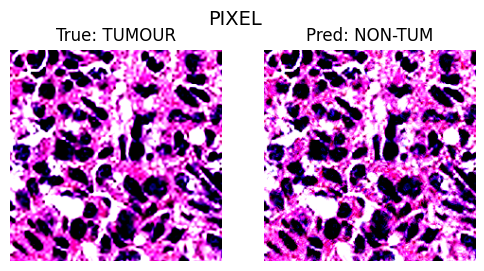

In [12]:
run_all_model_stats(
    model_evals=model_evals,
    root_dir=os.path.join(PATH, 'data', dataset_name),
    batch_size=8,
    test_multiplier=test_multiplier,
    runs=runs,
    device=device,
    PATH=PATH,
    save_dir_base=os.path.join(PATH, "Stats", "PanNuke"),
    dataset_class=dataclass,
    dataset_kwargs = kwargs
)

#### Compile stats csv

In [ ]:
# resnet_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "ResNet", "ResNet_stats.xlsx"))
# uni_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "UNI", "UNI_stats.xlsx"))
# uni2_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "UNI2", "UNI2_stats.xlsx"))
# gigapath_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "GigaPath", "GigaPath_stats.xlsx"))
# virchow_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "Virchow", "Virchow_stats.xlsx"))
# virchow2_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "Virchow2", "Virchow2_stats.xlsx"))
# hoptimus_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "H-Optimus-0", "H-Optimus-0_stats.xlsx"))
# exaonepath_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "EXAONEPath", "EXAONEPath_stats.xlsx"))
# hiboub_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "Hibou-B", "Hibou-B_stats.xlsx"))
# phikonv1_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "Phikon v1", "Phikon v1_stats.xlsx"))
# phikonv2_stats_df = pd.read_excel(os.path.join(PATH, "Stats", "PanNuke", "Phikon v2", "Phikon v2_stats.xlsx"))

In [ ]:
# all_stats = {
#     "ResNet": resnet_stats_df,
#     "UNI": uni_stats_df,
#     "UNI2": uni2_stats_df,
#     "GigaPath": gigapath_stats_df,
#     "Virchow": virchow_stats_df,
#     "Virchow2": virchow2_stats_df,
#     "H-Optimus-0": hoptimus_stats_df,
#     "EXAONEPath": exaonepath_stats_df,
#     "Hibou-B": hiboub_stats_df,
#     "Phikon v1": phikonv1_stats_df,
#     "Phikon v2": phikonv2_stats_df
# }

# output_filepath = os.path.join(PATH, "Stats", "PanNuke", "all_models_perturbation_stats.xlsx")

# with pd.ExcelWriter(output_filepath, engine="openpyxl") as writer:
#     for model_name, stats_df in all_stats.items():
#         # Write each DataFrame to a sheet named after the model
#         stats_df.to_excel(writer, sheet_name=model_name, index=True)

# print(f"Saved combined stats to: {output_filepath}")